# 02 · Data plan: domains, datasets, periods and cost

**Purpose of this notebook.** Before any large download, this notebook fixes *exactly* what is
downloaded (which regions, datasets and years) and tests every download on a short real sample, so
that domains, periods, units and grids can be checked and the full cost estimated in advance.

**How to read it.** Every code cell has a short note above it saying what it does and why.
Every figure has a caption underneath. The last section lists the design decisions this plan
fixes, with the reason for each.

**Sections**
1. The three analysis domains and the sub-regions
2. Every dataset in the plan
3. The paired experiments: observed and filtered sea-surface temperature
4. A small real sample from every source (speed, size, units, values)
5. Cost of the full download: time and disk space
6. Sample maps: do the cut-outs line up?
7. E-OBS station-based data
8. Known issues
9. Decisions fixed by this plan

**What this cell does.** Loads the project's own code from `src/eerie_uk/`. All the real work
(opening data, cutting boxes, converting units, plotting) lives there, so the notebook stays short.

In [1]:
import sys, dataclasses, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')

import pandas as pd
import xarray as xr
from eerie_uk import download as dl, plotting, regions

pd.set_option('display.max_colwidth', 90, 'display.width', 220, 'display.float_format', '{:.2f}'.format)

## 1. Domains

The analysis works on three nested scales: the large-scale circulation
(North Atlantic), the European response (north-west Europe), and the headline region (UK and Ireland).

**What this cell does.** Draws the three nested domains on one map, showing how much ocean
and land each one covers.

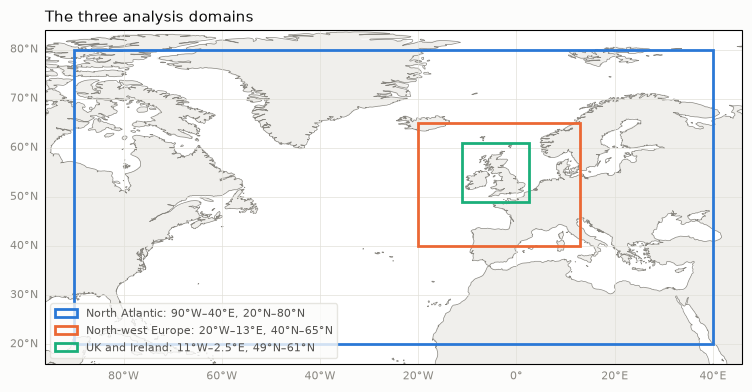

In [2]:
domains = {name: regions.BOXES[name] for name in regions.DOMAINS}
plotting.plot_boxes(domains, regions.LABELS, title='The three analysis domains');

**Figure 1.** The North Atlantic box is used only for sea-level pressure (the NAO pattern).
The north-west Europe box is what gets saved for temperature and precipitation. UK and Ireland
is cut out of the north-west Europe files later; it needs no separate download.

**What this cell does.** Zooms in on north-west Europe and shows the three sub-regions used
for headline numbers. The NAO makes the north wetter and the south drier (or the reverse), so one
average over the whole box would cancel out; sub-regions keep that contrast visible.

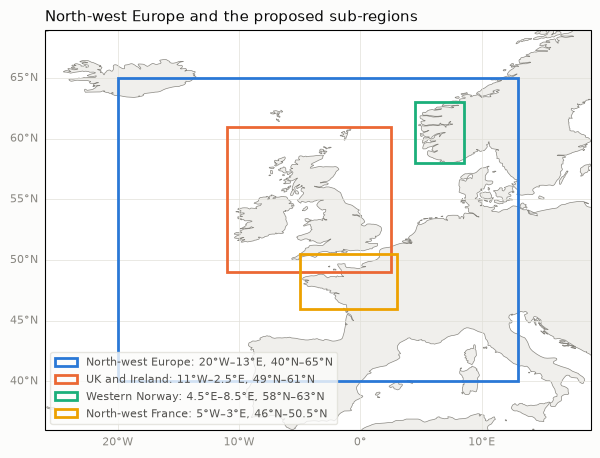

In [3]:
inner = {name: regions.BOXES[name] for name in ('nw_europe',) + regions.SUBREGIONS}
plotting.plot_boxes(inner, regions.LABELS, title='North-west Europe and the proposed sub-regions');

**Figure 2.** UK and Ireland is the headline region. Western Norway and north-west France are my
chosen as a wet northern and a drier southern counterpart. They can be moved without
downloading anything again, because they are cut from the north-west Europe files.

**What this cell does.** Lists every box with its exact limits and its size in grid points on the
0.25° grid, so the numbers on the maps are also available as a table.

In [4]:
box_table = pd.DataFrame([
    {'box': regions.LABELS[name], 'code name': name,
     'west': b[0], 'east': b[1], 'south': b[2], 'north': b[3],
     'grid points (lat x lon)': f'{int((b[3]-b[2])/0.25)+1} x {int((b[1]-b[0])/0.25)+1}',
     'role': 'download' if name in ('north_atlantic', 'nw_europe') else 'cut from nw_europe later'}
    for name, b in regions.BOXES.items()])
box_table

,box,code name,west,east,south,north,grid points (lat x lon),role
0,North Atlantic,north_atlantic,-90.00,40.00,20.00,80.00,241 x 521,download
1,North-west Europe,nw_europe,-20.00,13.00,40.00,65.00,101 x 133,download
2,UK and Ireland,uk_ireland,-11.00,2.50,49.00,61.00,49 x 55,cut from nw_europe later
3,Western Norway,western_norway,4.50,8.50,58.00,63.00,21 x 17,cut from nw_europe later
4,North-west France,nw_france,-5.00,3.00,46.00,50.50,19 x 33,cut from nw_europe later


## 2. Every dataset in the plan

The plan is defined in one place, `eerie_uk.download.build_plan()`. The downloader works through it
in order: all monthly data first (small and quick), then daily data.

**What this cell does.** Prints the full plan: one row per download. *server name* is what the
variable is called on the DKRZ server; *saved as* is the common name used in our files.
`coarsen = 4` means the field is averaged from 0.25° to 1° before saving (pressure only; the NAO is
a basin-wide pattern and does not need 0.25°).

In [5]:
plan = dl.build_plan()
plan_table = pd.DataFrame([{
    'source': r.source, 'frequency': r.frequency, 'server name': r.native, 'saved as': r.variable,
    'period': f'{r.start_year}-{r.end_year}', 'box': r.box, 'coarsen': r.coarsen, 'dataset on DKRZ': r.dataset_id,
} for r in plan])
print(len(plan), 'downloads in the plan')
plan_table

20 downloads in the plan


,source,frequency,server name,saved as,period,box,coarsen,dataset on DKRZ
0,icon-esm-er,mon,psl,psl,1950-2014,north_atlantic,4,icon-esm-er.hist-1950.v20240618.atmos.gr025.2d_monthly_mean
1,icon-esm-er,mon,tas,tas,1950-2014,nw_europe,1,icon-esm-er.hist-1950.v20240618.atmos.gr025.2d_monthly_mean
2,icon-esm-er,mon,pr,pr,1950-2014,nw_europe,1,icon-esm-er.hist-1950.v20240618.atmos.gr025.2d_monthly_mean
3,ifs-fesom2-sr,mon,mmsl,psl,1950-2014,north_atlantic,4,ifs-fesom2-sr.hist-1950.v20240304.atmos.gr025.2D_monthly_avg
4,ifs-fesom2-sr,mon,mean2t,tas,1950-2014,nw_europe,1,ifs-fesom2-sr.hist-1950.v20240304.atmos.gr025.2D_monthly_avg
5,ifs-fesom2-sr,mon,tprate,pr,1950-2014,nw_europe,1,ifs-fesom2-sr.hist-1950.v20240304.atmos.gr025.2D_monthly_avg
6,era5,mon,psl,psl,1950-2014,north_atlantic,4,era5-dkrz.surface_analysis_monthly
7,era5,mon,tas,tas,1950-2014,nw_europe,1,era5-dkrz.surface_analysis_monthly
8,era5,mon,tp,pr,1950-2014,nw_europe,1,era5-dkrz.surface_forecast_monthly
9,ifs-amip-tco1279.hist,mon,avg_msl,psl,1980-2023,north_atlantic,4,ifs-amip-tco1279.hist.v20240901.atmos.gr025.2D_monthly


**Reading the table.**
- `icon-esm-er` and `ifs-fesom2-sr` are the two coupled EERIE models, historical run, member r1.
- `era5` is the observation-based reference (reanalysis), from the same DKRZ server.
- `ifs-amip-...` are the paired atmosphere-only experiments explained in the next section.
- Monthly model and ERA5 data cover 1950–2014; daily data cover 1985–2014; the paired experiments
  cover the years they exist, 1980–2023.

## 3. The paired experiments: observed and filtered sea-surface temperature

The descriptions of these runs come from the public EERIE intake catalogue on GitHub (`dkrz/disk/model-output/ifs-amip-*/main.yaml`):

| Run | What the catalogue says |
|---|---|
| `ifs-amip-tco1279 . hist` | "high-resolution (tco1279, ~9 km) EERIE IFS-AMIP historical production run, forced with ESA-CCI v3 SST & sea ice" |
| `ifs-amip-tco1279 . hist-c-0-a-lr20` | the same, "*filtered anomalies* ... SST anomalies are filtered with LR20" |
| `ifs-amip-tco399 . hist` | "medium-resolution (tco399, ~28 km)" version of the historical run |
| `ifs-amip-tco399 . hist-c-0-a-lr20` | medium-resolution run with filtered SST anomalies |
| `ifs-amip-tco399 . hist-c-lr20-a-0` | third medium-resolution variant; not described in the catalogue |

**What that means.** These are atmosphere-only runs: the same atmosphere model, given observed
sea-surface temperature in one run and a *smoothed* version (small-scale ocean features filtered
out) in the other. That is a controlled test of the atmosphere's sensitivity to small-scale SST
variability.

**What the server provides.** Monthly `avg_msl` (pressure), `mean2t`, `mx2t`, `tprate` on the
0.25° grid for 1980–2023. Daily mean temperature and precipitation exist, but daily *maximum*
temperature does not on this grid. The ~28 km runs come as **10 members each**, which is very
valuable for a noisy quantity like the NAO.

**Use in this project:** monthly pressure for the NAO (notebook 07). Daily precipitation of the
9 km and 28 km historical runs is used later for the resolution comparison (notebook 08).

**Two things not verified:** exactly what the "LR20" filter is (presumably a low-pass
spatial filter; the catalogue does not define it), and what `hist-c-lr20-a-0` changes. The name
suggests the filter is applied to the climatology instead of the anomalies. Both need the EERIE
documentation before any result from these runs is interpreted.

## 4. A small real sample from every source

Before committing to hours of downloading, each of the downloads in the plan is tried on a short
period: January–March 1990 for monthly data, 1–10 January 1990 for daily data.

**What this cell does.** Runs the short sample for every row of the plan, using exactly the same
code path as the real download (open → cut to the box → convert units → save compressed netCDF).
It records how long each time step took and how big the saved file is. This is the slowest cell
in the notebook (a few minutes).

In [6]:
rows = []
for r in plan:
    start, end = ('1990-01-01', '1990-03-31T23:59:59') if r.frequency == 'mon' else ('1990-01-01', '1990-01-10T23:59:59')
    rows.append(dl.measure(r, start, end, '../data'))
samples = pd.DataFrame(rows)
print(int(samples.ok.sum()), 'of', len(samples), 'samples succeeded')
samples[['source', 'frequency', 'variable', 'box', 'ok', 'error']]

20 of 20 samples succeeded


,source,frequency,variable,box,ok,error
0,icon-esm-er,mon,psl,north_atlantic,True,
1,icon-esm-er,mon,tas,nw_europe,True,
2,icon-esm-er,mon,pr,nw_europe,True,
3,ifs-fesom2-sr,mon,psl,north_atlantic,True,
4,ifs-fesom2-sr,mon,tas,nw_europe,True,
5,ifs-fesom2-sr,mon,pr,nw_europe,True,
6,era5,mon,psl,north_atlantic,True,
7,era5,mon,tas,nw_europe,True,
8,era5,mon,pr,nw_europe,True,
9,ifs-amip-tco1279.hist,mon,psl,north_atlantic,True,


**How to read this.** `ok = True` means the sample was downloaded, cut, converted and saved.
Any failure shows the exact error message in the last column.

**What this cell does.** Shows what came back for each sample: the saved grid size, how many
ensemble members, the units on the server and after conversion, and the smallest / average /
largest value. This is the quick sanity check that units and values are physically sensible.

In [7]:
good = samples[samples.ok]
good[['source', 'frequency', 'variable', 'box', 'grid', 'members', 'server_units', 'units', 'min', 'mean', 'max', 'missing']]

,source,frequency,variable,box,grid,members,server_units,units,min,mean,max,missing
0,icon-esm-er,mon,psl,north_atlantic,60 x 130,1,Pa,hPa,978.87,1011.15,1034.96,0
1,icon-esm-er,mon,tas,nw_europe,101 x 133,1,K,K,255.42,277.72,285.98,0
2,icon-esm-er,mon,pr,nw_europe,101 x 133,1,kg m-2 s-1,mm/day,0.03,3.85,27.69,0
3,ifs-fesom2-sr,mon,psl,north_atlantic,60 x 130,1,Pa,hPa,986.42,1014.82,1033.10,0
4,ifs-fesom2-sr,mon,tas,nw_europe,101 x 133,1,K,K,256.12,278.07,286.96,0
5,ifs-fesom2-sr,mon,pr,nw_europe,101 x 133,1,m s**-1,mm/day,0.01,3.78,18.57,0
6,era5,mon,psl,north_atlantic,60 x 130,1,Pa,hPa,974.89,1010.79,1029.68,0
7,era5,mon,tas,nw_europe,101 x 133,1,K,K,261.26,280.53,288.18,0
8,era5,mon,pr,nw_europe,101 x 133,1,m,mm/day,0.01,3.82,25.12,0
9,ifs-amip-tco1279.hist,mon,psl,north_atlantic,60 x 130,1,Pa,hPa,984.24,1013.01,1028.58,0


**What sensible values look like.** Winter sea-level pressure around 1010–1015 hPa on average;
winter temperature in north-west Europe around 275–285 K (2–12 °C); average precipitation a few
mm/day with daily maxima of tens of mm/day. `missing` should be 0.

**Unit conversions applied** (`eerie_uk.download.convert_units`):

| Quantity | On the server | Saved as | Conversion |
|---|---|---|---|
| Precipitation, ICON-ESM-ER | kg m⁻² s⁻¹ | mm/day | × 86 400 |
| Precipitation, IFS-FESOM2-SR | m s⁻¹ | mm/day | × 86 400 × 1000 |
| Precipitation, ERA5 | m (per day) | mm/day | × 1000 |
| Pressure | Pa | hPa | ÷ 100 |
| Temperature | K | K | none |

## 5. Cost of the full download

The sample speeds are scaled up to the full periods. These are estimates: the server speed varies.

**What this cell does.** Multiplies the measured seconds-per-time-step and megabytes-per-time-step
by the number of time steps in each full download, giving hours and gigabytes per row and in total.

In [8]:
cost_rows = []
for r, s in zip(plan, rows):
    if not s['ok']:
        continue
    c = dl.estimate(r, s['seconds_per_step'], s['mb_per_step'])
    cost_rows.append({'source': r.source, 'frequency': r.frequency, 'variable': r.variable, 'box': r.box,
                      'period': f'{r.start_year}-{r.end_year}', 'time steps': c['steps'],
                      'seconds per step': s['seconds_per_step'], 'hours': c['hours'], 'GB on disk': c['gb']})
cost = pd.DataFrame(cost_rows)
totals = cost.groupby('frequency')[['hours', 'GB on disk']].sum()
totals.loc['total'] = totals.sum()
print(totals.round(2).to_string())
cost

           hours  GB on disk
frequency                   
day        21.93        2.52
mon         8.93        0.57
total      30.85        3.09


,source,frequency,variable,box,period,time steps,seconds per step,hours,GB on disk
0,icon-esm-er,mon,psl,north_atlantic,1950-2014,780,3.37,0.73,0.02
1,icon-esm-er,mon,tas,nw_europe,1950-2014,780,1.16,0.25,0.03
2,icon-esm-er,mon,pr,nw_europe,1950-2014,780,1.38,0.30,0.04
3,ifs-fesom2-sr,mon,psl,north_atlantic,1950-2014,780,1.60,0.35,0.02
4,ifs-fesom2-sr,mon,tas,nw_europe,1950-2014,780,1.04,0.23,0.03
5,ifs-fesom2-sr,mon,pr,nw_europe,1950-2014,780,1.50,0.32,0.04
6,era5,mon,psl,north_atlantic,1950-2014,780,5.37,1.16,0.02
7,era5,mon,tas,nw_europe,1950-2014,780,4.77,1.03,0.03
8,era5,mon,pr,nw_europe,1950-2014,780,5.24,1.14,0.04
9,ifs-amip-tco1279.hist,mon,psl,north_atlantic,1980-2023,528,1.63,0.24,0.01


**What this cell does.** Shows the estimated download time per row as a bar chart, so the
expensive downloads stand out at a glance.

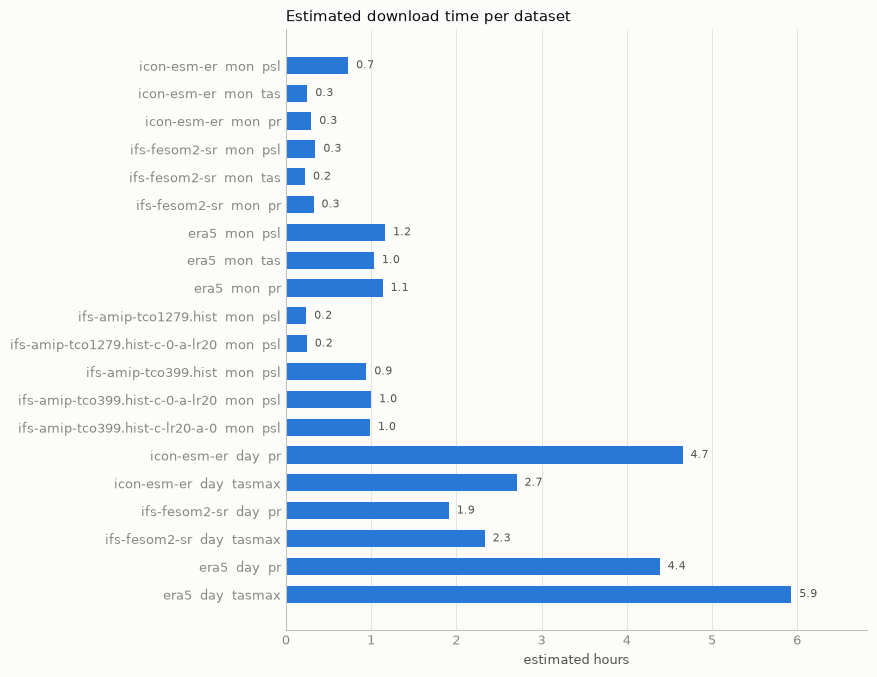

In [9]:
labels = cost.source + '  ' + cost.frequency + '  ' + cost.variable
plotting.plot_bars(dict(zip(labels, cost.hours)), xlabel='estimated hours', title='Estimated download time per dataset');

**Figure 3.** Estimated hours for each download. The six daily downloads dominate; all the monthly
ones together are small.

**What this cell does.** The same chart for disk space, to confirm the plan fits comfortably on
an ordinary laptop disk.

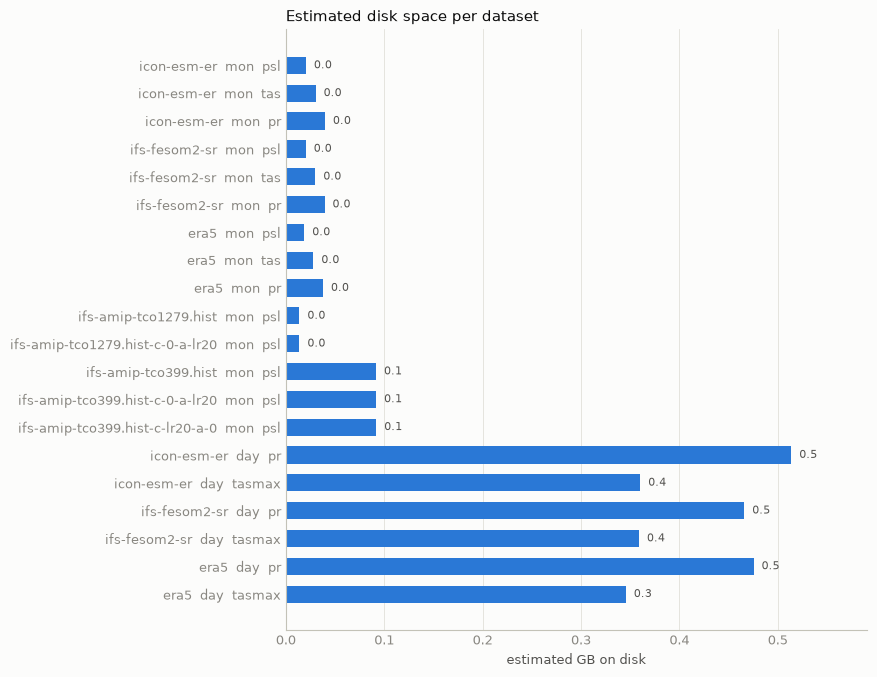

In [10]:
plotting.plot_bars(dict(zip(labels, cost['GB on disk'])), xlabel='estimated GB on disk', title='Estimated disk space per dataset');

**Figure 4.** Estimated size of the saved files. The whole-globe data the server sends is never
written to disk; only these cut-outs are.

## 6. Sample maps: do the cut-outs line up?

The maps below are drawn from the sample files just saved. Free-running climate models do not
reproduce the real weather of a given day or month, so the models and ERA5 are **not expected to
match** in detail for January 1990. What should match is the region, the grid, the units and the
general magnitude.

**What this cell does.** Defines a small helper that opens the saved sample files for one variable
and returns one map per source (first time step; first member where a run has several).

In [11]:
def sample_maps(frequency, variable, reduce='first'):
    maps = {}
    for s in rows:
        if s['ok'] and s['frequency'] == frequency and s['variable'] == variable:
            field = xr.open_dataarray(s['path']).load()
            if 'realization' in field.dims:
                field = field.isel(realization=0)
            maps[s['source']] = field.isel(time=0) if reduce == 'first' else field.mean('time')
    return maps

**What this cell does.** Maps January 1990 mean sea-level pressure over the North Atlantic box for
every source, on one shared colour scale. This is the field the NAO will be computed from.

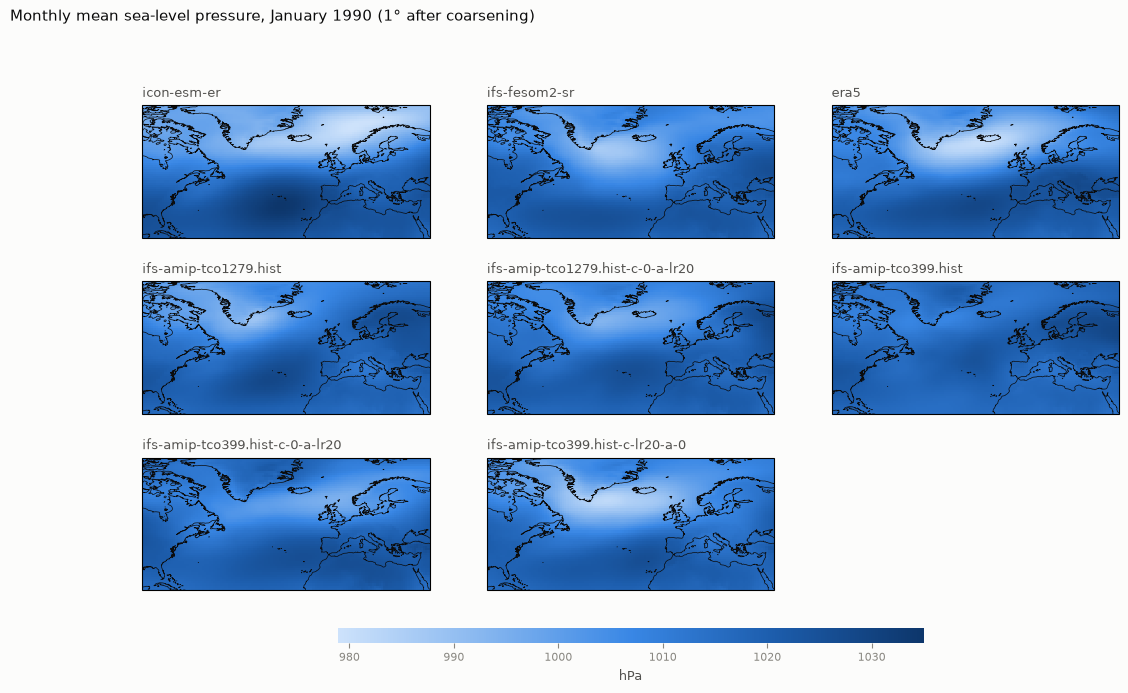

In [12]:
plotting.plot_field_panels(sample_maps('mon', 'psl'), units='hPa', title='Monthly mean sea-level pressure, January 1990 (1° after coarsening)');

**Figure 5.** Every source shows the expected winter pattern: low pressure near Iceland, high
pressure near the Azores. All panels cover the same box on the same 1° grid. For the 10-member
runs only the first member is shown.

**What this cell does.** Maps January 1990 mean 2 m temperature over north-west Europe for the two
coupled models and ERA5.

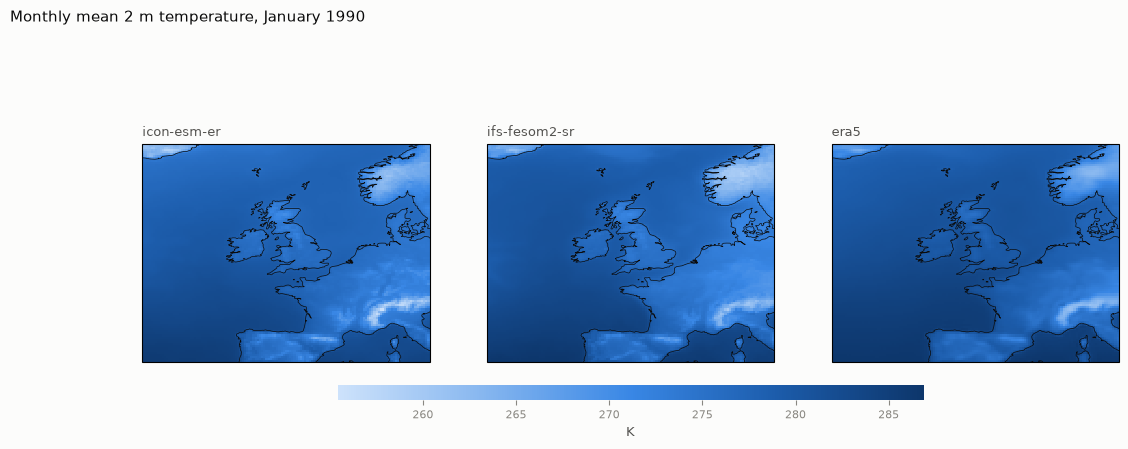

In [13]:
plotting.plot_field_panels(sample_maps('mon', 'tas'), units='K', title='Monthly mean 2 m temperature, January 1990');

**Figure 6.** Mild ocean, cold Scandinavia and Alps in all three. The ERA5 panel has been
interpolated from ERA5's own grid to the same 0.25° grid as the models.

**What this cell does.** Maps January 1990 mean precipitation, after conversion to mm/day, to check
that the three different server units ended up on the same scale.

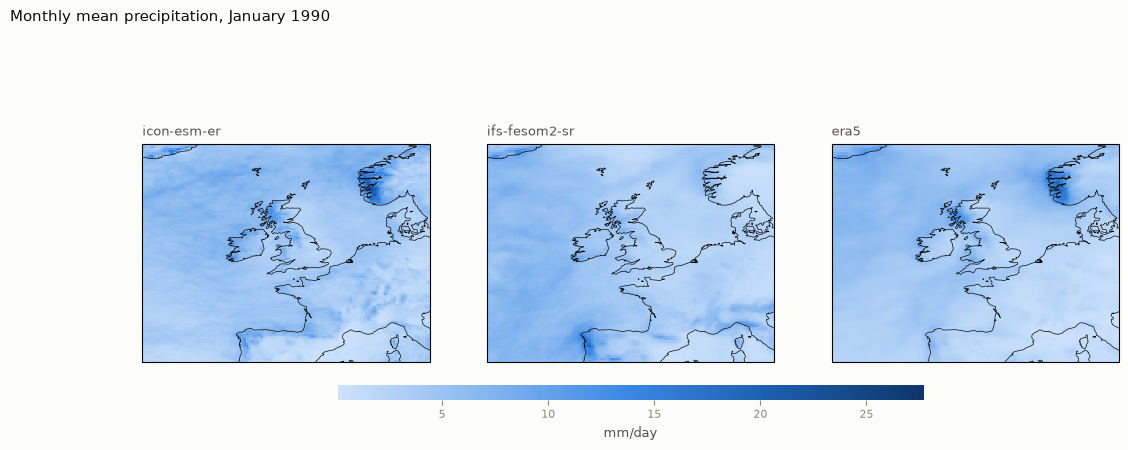

In [14]:
plotting.plot_field_panels(sample_maps('mon', 'pr'), units='mm/day', title='Monthly mean precipitation, January 1990');

**Figure 7.** Similar magnitudes in all three sources, with the wettest values on west-facing
coasts and mountains. If one unit conversion were wrong, that panel would be off by a factor of
1000 or 86 400 and would show as blank or saturated.

**What this cell does.** Maps daily precipitation averaged over the 10 sample days
(1–10 January 1990), from the daily files. These are the data the precipitation extremes
(RX1day, R95p) will be computed from.

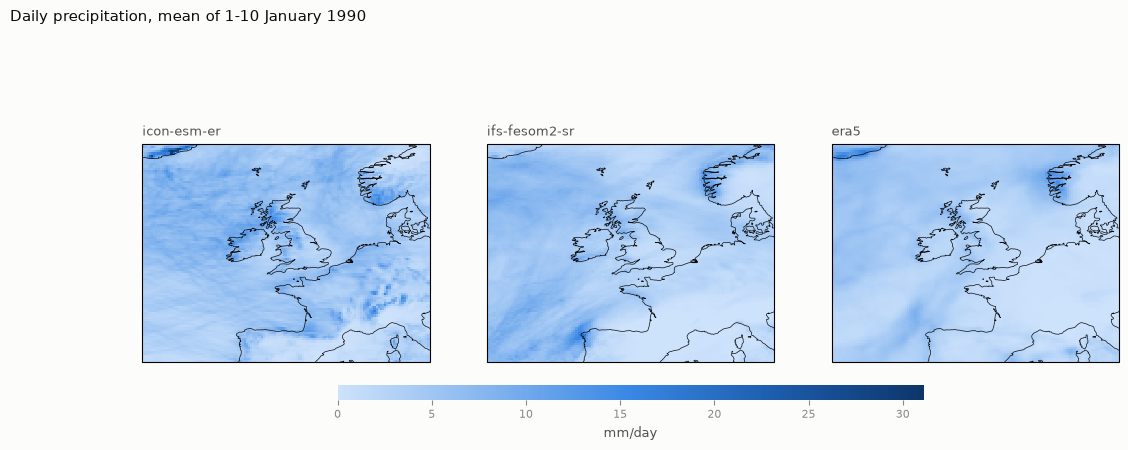

In [15]:
plotting.plot_field_panels(sample_maps('day', 'pr', reduce='mean'), units='mm/day', title='Daily precipitation, mean of 1-10 January 1990');

**Figure 8.** Ten-day means from the daily data. The weather differs between panels because each
model has its own storms; only the scale and the geography should agree.

**What this cell does.** The same for daily maximum temperature, the input for TXx.

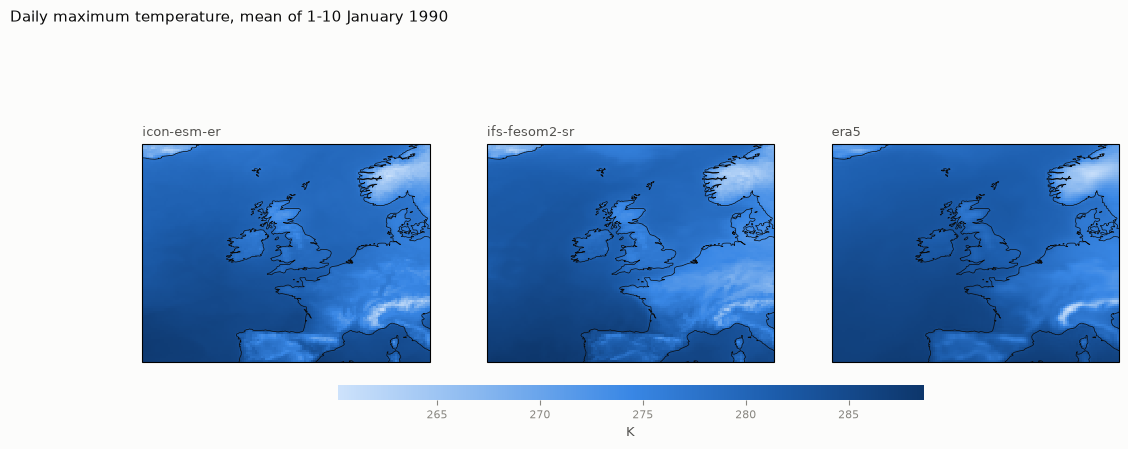

In [16]:
plotting.plot_field_panels(sample_maps('day', 'tasmax', reduce='mean'), units='K', title='Daily maximum temperature, mean of 1-10 January 1990');

**Figure 9.** Ten-day mean of daily maximum temperature. Land–sea contrast and mountains appear in
the same places in all three.

## 7. E-OBS station-based data

E-OBS is used as the land reference for extremes. It is distributed as two files:

| File | Content | Size |
|---|---|---|
| `rr_ens_mean_0.25deg_reg_v33.0e.nc` | daily precipitation, Europe, 0.25°, 1950 onwards | 704 MB |
| `tx_ens_mean_0.25deg_reg_v33.0e.nc` | daily maximum temperature, same grid | 857 MB |

Source: the ECA&D / Copernicus E-OBS access page (`surfobs.climate.copernicus.eu`). These are single
files for the whole of Europe and the whole period, so about 1.6 GB to download in one go. They are
cut to the north-west Europe box and the originals deleted (`eerie_uk.eobs`).

**Terms of use.** The data are "strictly for use in non-commercial research and non-commercial
education projects" (ECA&D data policy). E-OBS is land-only, on the same 0.25° grid as the models, and is a more direct observation of
extremes than ERA5, whose precipitation comes from a forecast model.

## 8. Known issues

- **Estimates, not guarantees.** Download times come from samples of 3 time steps (monthly) or
  10 (daily). The server was sometimes several times slower in earlier tests.
- **Connection drops.** Short network failures (for example `getaddrinfo failed`) do occur. The downloader retries each year three times and skips years already
  saved, so a rerun simply continues.
- **ERA5 is interpolated.** ERA5 is stored on its own grid (rows of different length); it is interpolated
  linearly to 0.25°. That slightly smooths sharp precipitation maxima.
- **ERA5 precipitation is a model product.** It is not a direct observation. E-OBS would be the
  better reference for RX1day and R95p over land.
- **Time stamps differ.** ICON-ESM-ER stamps a month at its end (31 January 23:59), IFS at mid-month,
  ERA5 at the first of the month. This is handled when years and seasons are selected, but it is a
  place where mistakes can hide, so notebook 03 checks it explicitly.
- **Model calendars are real calendars** (with leap days), so no calendar conversion is needed.
- **Only member r1** of each coupled model is in the plan. Members r2 and r3 (1975–2014) exist and
  could be added for the NAO at small cost.
- **Paired experiments:** the meaning of "LR20" and of `hist-c-lr20-a-0` is not yet verified
  (section 3).
- **Later additions.** Daily pressure (for notebook 09) and daily precipitation of the 9 km and
  28 km atmosphere-only runs (for notebook 08) were added later, defined in
  `eerie_uk.download.build_extension_plan()`. To limit network traffic, the 28 km run uses its
  first three members and winter months only.

## 9. Decisions fixed by this plan

| Decision | Choice | Reason |
|---|---|---|
| Domains | North Atlantic 90°W–40°E, 20–80°N (pressure); north-west Europe 20°W–13°E, 40–65°N (temperature, precipitation); UK and Ireland 11°W–2.5°E, 49–61°N | Large-scale circulation, European response, headline region (README, section 1) |
| Sub-regions | UK and Ireland, western Norway, north-west France | The two sides of the NAO rainfall see-saw around the headline region |
| Periods | Monthly 1950–2014; daily 1985–2014; paired experiments 1980–2023 | 64 winters for the NAO; a standard 30-year period for extremes; the full span of the experiments |
| Sources | ICON-ESM-ER r1, IFS-FESOM2-SR r1, ERA5, E-OBS, IFS atmosphere-only runs | The only public EERIE runs with all fields needed (notebook 01) |
| Pressure resolution | 1° instead of 0.25° | Ample for the NAO, 16 times smaller on disk |
| Storage | Compressed netCDF, one file per source, variable, region and year | A failed download costs one year; reruns resume |